##### **05 — Modelagem e Avaliação**

**Objetivo:** treinar uma regressão logística com fórmula (`statsmodels.formula.api`), avaliar significância, aplicar stepwise backward e comparar o modelo completo com o reduzido.

**Entrada:** `data/02_gold/*_selecionado.parquet` e `variaveis_selecionadas.json`  
**Saída:** modelos, histórico do stepwise, comparação, métricas, scores e lista final de variáveis.

In [56]:
import json
import pickle

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import statsmodels.formula.api as smf
from sklearn.metrics import (
    roc_auc_score, roc_curve, confusion_matrix,
    brier_score_loss, log_loss,
)
from sklearn.model_selection import KFold
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import SplineTransformer
from sklearn.pipeline import make_pipeline
from sklearn.isotonic import IsotonicRegression
from statsmodels.stats.outliers_influence import variance_inflation_factor

pd.set_option("display.max_columns", None)

#### **1. Carga das bases selecionadas**

In [57]:
treino = pd.read_parquet("../data/02_gold/treino_selecionado.parquet")
validacao = pd.read_parquet("../data/02_gold/validacao_selecionado.parquet")
teste = pd.read_parquet("../data/02_gold/teste_selecionado.parquet")

with open("../data/02_gold/variaveis_selecionadas.json") as file:
    variaveis = json.load(file)

target = "default"

print("Variáveis disponíveis:", len(variaveis))
print(variaveis)

Variáveis disponíveis: 16
['AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT6', 'SUM_BILL', 'MAX_BILL', 'UTIL_MEDIA', 'PCT_PAGAMENTO', 'LIMIT_PER_CAPITA']


#### **2. Modelo completo com fórmula**

In [93]:
formula_completa = f"{target} ~ " + " + ".join(variaveis)
modelo_completo = smf.logit(formula_completa, data=treino).fit(disp=0)

print(modelo_completo.summary())

                           Logit Regression Results                           
Dep. Variable:                default   No. Observations:                18000
Model:                          Logit   Df Residuals:                    17983
Method:                           MLE   Df Model:                           16
Date:                Sat, 31 Oct 2026   Pseudo R-squ.:                  0.1689
Time:                        10:20:25   Log-Likelihood:                -8077.5
converged:                       True   LL-Null:                       -9719.0
Covariance Type:            nonrobust   LLR p-value:                     0.000
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           -1.2003      0.020    -59.643      0.000      -1.240      -1.161
AGE                 -0.3673      0.132     -2.791      0.005      -0.625      -0.109
PAY_0               -0.7570 

In [59]:
tabela_completa = pd.DataFrame({
    "variavel": modelo_completo.params.index,
    "coef": modelo_completo.params.values,
    "p_value": modelo_completo.pvalues.values,
    "std_err": modelo_completo.bse.values,
    "z": modelo_completo.tvalues.values,
}).sort_values("p_value", ascending=False)

tabela_completa["significativo_5pct"] = tabela_completa["p_value"] < 0.05
tabela_completa

,variavel,coef,p_value,std_err,z,significativo_5pct
12,SUM_BILL,0.032168,8.508510e-01,0.171076,0.188033,False
3,PAY_2,-0.018291,6.898793e-01,0.045841,-0.399019,False
10,PAY_AMT3,-0.123813,1.393324e-01,0.083755,-1.478282,False
5,PAY_4,-0.097179,9.141514e-02,0.057571,-1.687980,False
15,PCT_PAGAMENTO,0.176042,4.546382e-02,0.088006,2.000338,True
11,PAY_AMT6,-0.164067,4.400633e-02,0.081462,-2.014031,True
13,MAX_BILL,-0.329286,2.912039e-02,0.150920,-2.181853,True
9,PAY_AMT2,-0.183316,1.363523e-02,0.074316,-2.466732,True
7,PAY_6,-0.140437,6.205140e-03,0.051316,-2.736740,True
1,AGE,-0.367265,5.259728e-03,0.131604,-2.790681,True


#### **3. Stepwise backward por p-value**

A cada iteração, remove a variável com maior p-value enquanto ela estiver acima de `0.05`. O processo usa **somente o treino**.

In [60]:
def stepwise_logit(data, target, variaveis, limite_p=0.05):
    selecionadas = variaveis.copy()
    historico = []

    while True:
        formula = f"{target} ~ " + " + ".join(selecionadas)
        modelo = smf.logit(formula, data=data).fit(disp=0)
        pvalues = modelo.pvalues.drop("Intercept")
        maior_p = pvalues.max()

        if maior_p <= limite_p:
            break

        removida = pvalues.idxmax()
        historico.append({
            "variavel_removida": removida,
            "p_value": maior_p,
            "aic": modelo.aic,
            "bic": modelo.bic,
        })
        selecionadas.remove(removida)

    return selecionadas, modelo, pd.DataFrame(historico)

In [61]:
variaveis_reduzidas, modelo_reduzido, historico_stepwise = stepwise_logit(
    treino,
    target,
    variaveis,
    limite_p=0.05,
)

print("Variáveis removidas:", historico_stepwise["variavel_removida"].tolist())
print("Variáveis mantidas:", variaveis_reduzidas)
historico_stepwise

Variáveis removidas: ['SUM_BILL', 'PAY_2', 'PAY_AMT3', 'PCT_PAGAMENTO']
Variáveis mantidas: ['AGE', 'PAY_0', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT6', 'MAX_BILL', 'UTIL_MEDIA', 'LIMIT_PER_CAPITA']


,variavel_removida,p_value,aic,bic
0,SUM_BILL,0.850851,16189.068124,16321.636284
1,PAY_2,0.678401,16187.103453,16311.873486
2,PAY_AMT3,0.150116,16185.275298,16302.247204
3,PCT_PAGAMENTO,0.052198,16185.345022,16294.518801


#### **4. Modelo reduzido**

In [62]:
formula_reduzida = f"{target} ~ " + " + ".join(variaveis_reduzidas)
modelo_reduzido = smf.logit(formula_reduzida, data=treino).fit(disp=0)

print(modelo_reduzido.summary())

                           Logit Regression Results                           
Dep. Variable:                default   No. Observations:                18000
Model:                          Logit   Df Residuals:                    17987
Method:                           MLE   Df Model:                           12
Date:                Sat, 31 Oct 2026   Pseudo R-squ.:                  0.1686
Time:                        10:16:45   Log-Likelihood:                -8080.6
converged:                       True   LL-Null:                       -9719.0
Covariance Type:            nonrobust   LLR p-value:                     0.000
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           -1.1964      0.020    -59.782      0.000      -1.236      -1.157
AGE                 -0.3662      0.132     -2.783      0.005      -0.624      -0.108
PAY_0               -0.7575 

In [63]:
tabela_reduzida = pd.DataFrame({
    "variavel": modelo_reduzido.params.index,
    "coef": modelo_reduzido.params.values,
    "p_value": modelo_reduzido.pvalues.values,
    "std_err": modelo_reduzido.bse.values,
    "z": modelo_reduzido.tvalues.values,
}).sort_values("p_value", ascending=False)

tabela_reduzida["significativo_5pct"] = tabela_reduzida["p_value"] < 0.05
tabela_reduzida

,variavel,coef,p_value,std_err,z,significativo_5pct
9,PAY_AMT6,-0.189326,1.788669e-02,0.079953,-2.367955,True
4,PAY_4,-0.133102,1.137935e-02,0.052592,-2.530828,True
6,PAY_6,-0.142006,5.620555e-03,0.051282,-2.769134,True
1,AGE,-0.366234,5.380296e-03,0.131581,-2.783337,True
8,PAY_AMT2,-0.211522,3.310141e-03,0.072011,-2.937365,True
3,PAY_3,-0.155580,8.979950e-04,0.046852,-3.320677,True
10,MAX_BILL,-0.422359,6.494702e-04,0.123857,-3.410067,True
7,PAY_AMT1,-0.196061,6.045564e-04,0.057168,-3.429562,True
5,PAY_5,-0.241311,4.227632e-06,0.052461,-4.599866,True
12,LIMIT_PER_CAPITA,-0.323978,2.338274e-08,0.058010,-5.584905,True


In [64]:
X_reduzido = treino[variaveis_reduzidas]
X_reduzido_centrado = X_reduzido - X_reduzido.mean()

vif_reduzido = pd.Series(
    [
        variance_inflation_factor(X_reduzido_centrado.values, i)
        for i in range(X_reduzido.shape[1])
    ],
    index=variaveis_reduzidas,
).sort_values(ascending=False)

vif_reduzido

PAY_4               2.502711
PAY_5               2.474279
PAY_3               2.217980
PAY_AMT2            1.917854
PAY_6               1.820201
MAX_BILL            1.659851
PAY_AMT1            1.610285
PAY_AMT6            1.496865
PAY_0               1.428501
LIMIT_PER_CAPITA    1.349804
UTIL_MEDIA          1.128263
AGE                 1.093179
dtype: float64

#### **5. Comparação entre modelo completo e reduzido**

In [65]:
def avaliar_modelo(modelo, base, nome):
    prob = modelo.predict(base)
    y = base[target]

    auc = roc_auc_score(y, prob)
    fpr, tpr, _ = roc_curve(y, prob)
    ks = max(tpr - fpr)
    gini = 2 * auc - 1

    return {
        "base": nome,
        "n": len(base),
        "bad_rate": y.mean(),
        "auc": auc,
        "ks": ks,
        "gini": gini,
    }, prob

In [66]:
comparacao = []

for nome_modelo, modelo, variaveis_modelo in [
    ("completo", modelo_completo, variaveis),
    ("reduzido", modelo_reduzido, variaveis_reduzidas),
]:
    for nome_base, base in [("treino", treino), ("validacao", validacao)]:
        resumo, _ = avaliar_modelo(modelo, base, nome_base)
        resumo["modelo"] = nome_modelo
        resumo["n_variaveis"] = len(variaveis_modelo)
        resumo["aic"] = modelo.aic
        resumo["bic"] = modelo.bic
        comparacao.append(resumo)

comparacao_modelos = pd.DataFrame(comparacao)
comparacao_modelos = comparacao_modelos[[
    "modelo", "n_variaveis", "base", "n", "bad_rate",
    "auc", "ks", "gini", "aic", "bic",
]]

comparacao_modelos.round(4)

,modelo,n_variaveis,base,n,bad_rate,auc,ks,gini,aic,bic
0,completo,16,treino,18000,0.2306,0.7686,0.4095,0.5372,16189.0681,16321.6363
1,completo,16,validacao,6000,0.2033,0.7787,0.4188,0.5574,16189.0681,16321.6363
2,reduzido,12,treino,18000,0.2306,0.7683,0.4073,0.5366,16187.1380,16288.5136
3,reduzido,12,validacao,6000,0.2033,0.7781,0.4193,0.5562,16187.1380,16288.5136


#### **6. Escolha do modelo final**

O modelo reduzido é escolhido por parcimônia. A avaliação abaixo mostra que a performance na validação é praticamente equivalente.

In [67]:
modelo_final = modelo_reduzido
variaveis_finais = variaveis_reduzidas
formula_final = formula_reduzida

print("Modelo final: reduzido")
print("Variáveis finais:", len(variaveis_finais))
print(variaveis_finais)

Modelo final: reduzido
Variáveis finais: 12
['AGE', 'PAY_0', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT6', 'MAX_BILL', 'UTIL_MEDIA', 'LIMIT_PER_CAPITA']


#### **7. Avaliação final no treino, validação e teste**

In [68]:
metricas = []
resultados = {}

for nome, base in [("treino", treino), ("validacao", validacao), ("teste", teste)]:
    resumo, prob = avaliar_modelo(modelo_final, base, nome)
    metricas.append(resumo)
    resultados[nome] = prob

metricas = pd.DataFrame(metricas)
metricas.round(4)

,base,n,bad_rate,auc,ks,gini
0,treino,18000,0.2306,0.7683,0.4073,0.5366
1,validacao,6000,0.2033,0.7781,0.4193,0.5562
2,teste,6000,0.2110,0.7906,0.4384,0.5812


#### **8. Curva ROC**

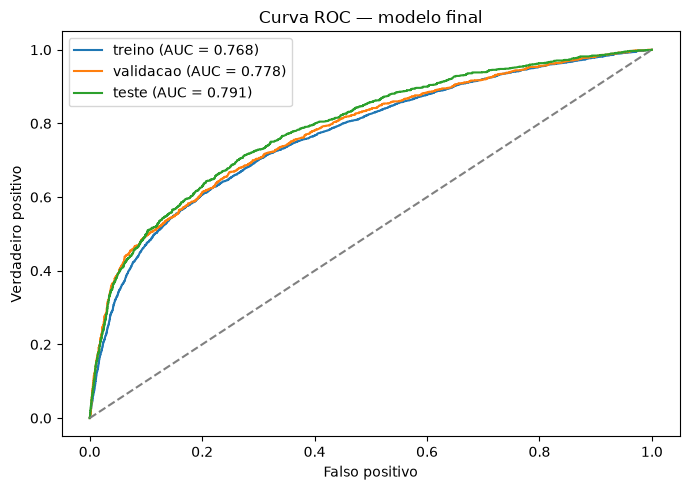

In [69]:
plt.figure(figsize=(7, 5))

for nome, base in [("treino", treino), ("validacao", validacao), ("teste", teste)]:
    fpr, tpr, _ = roc_curve(base[target], resultados[nome])
    auc = roc_auc_score(base[target], resultados[nome])
    plt.plot(fpr, tpr, label=f"{nome} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("Falso positivo")
plt.ylabel("Verdadeiro positivo")
plt.title("Curva ROC — modelo final")
plt.legend()
plt.tight_layout()
plt.show()

#### **9. Ponto de corte na validação**

In [70]:
fpr_val, tpr_val, thresholds_val = roc_curve(validacao[target], resultados["validacao"])
indice_corte = np.argmax(tpr_val - fpr_val)
corte = thresholds_val[indice_corte]

print("Corte escolhido na validação:", round(corte, 4))

predito_teste = (resultados["teste"] >= corte).astype(int)
matriz_teste = confusion_matrix(teste[target], predito_teste)

pd.DataFrame(
    matriz_teste,
    index=["Real 0", "Real 1"],
    columns=["Predito 0", "Predito 1"],
)

Corte escolhido na validação: 0.1825


,Predito 0,Predito 1
Real 0,3543,1191
Real 1,398,868


#### **10. Gravação dos resultados**

In [71]:
comparacao_modelos.to_csv("../data/02_gold/comparacao_modelos.csv", index=False)
historico_stepwise.to_csv("../data/02_gold/stepwise_historico.csv", index=False)
metricas.to_csv("../data/02_gold/metricas_modelo.csv", index=False)

with open("../data/02_gold/variaveis_stepwise.json", "w") as file:
    json.dump(variaveis_finais, file, indent=2)

with open("../data/02_gold/modelo_logistico_completo.pkl", "wb") as file:
    pickle.dump(modelo_completo, file, protocol=pickle.HIGHEST_PROTOCOL)

with open("../data/02_gold/modelo_logistico_reduzido.pkl", "wb") as file:
    pickle.dump(modelo_reduzido, file, protocol=pickle.HIGHEST_PROTOCOL)

with open("../data/02_gold/modelo_logistico.pkl", "wb") as file:
    pickle.dump(modelo_final, file, protocol=pickle.HIGHEST_PROTOCOL)

scores_teste = teste[["ID", "SAFRA", target]].copy()
scores_teste["prob_default"] = resultados["teste"]
scores_teste["predito"] = (scores_teste["prob_default"] >= corte).astype(int)
scores_teste.to_parquet("../data/02_gold/scores_teste.parquet", index=False)

print("Arquivos gravados em data/02_gold")

Arquivos gravados em data/02_gold


In [72]:
metricas.round(4)

,base,n,bad_rate,auc,ks,gini
0,treino,18000,0.2306,0.7683,0.4073,0.5366
1,validacao,6000,0.2033,0.7781,0.4193,0.5562
2,teste,6000,0.2110,0.7906,0.4384,0.5812


#### **11. Avaliação para negócios**

Esta seção traduz o modelo para a linguagem de negócio:

- **Curva de ganhos acumulados:** quanto dos maus pagadores é capturado ao priorizar os maiores riscos;
- **Lift:** quantas vezes o risco de cada decil é maior que a média da carteira;
- **Calibração:** probabilidade prevista vs bad rate observado;
- **Distribuição de score:** separação entre bons e maus.

A avaliação abaixo usa o **teste/OOT**.

In [73]:
import os

GREEN_DARK = "#1B4D3E"
GREEN_MID = "#2E8B57"
GREEN_PALE = "#A3E4D7"

os.makedirs("../reports", exist_ok=True)

In [74]:
def tabela_decisao(base, probabilidades, n_bins=10):
    df = base[[target]].copy()
    df["prob"] = probabilidades
    df = df.sort_values("prob", ascending=False).reset_index(drop=True)
    df["decil"] = pd.qcut(df.index, n_bins, labels=False) + 1

    total_bads = df[target].sum()

    tabela = df.groupby("decil").agg(
        n=(target, "size"),
        bads=(target, "sum"),
        bad_rate=(target, "mean"),
        prob_media=("prob", "mean"),
        prob_min=("prob", "min"),
        prob_max=("prob", "max"),
    ).reset_index()

    tabela["pct_populacao"] = tabela["n"] / tabela["n"].sum()
    tabela["pct_bads"] = tabela["bads"] / total_bads
    tabela["bad_rate_geral"] = df[target].mean()
    tabela["lift"] = tabela["bad_rate"] / tabela["bad_rate_geral"]
    tabela["bads_acum"] = tabela["bads"].cumsum()
    tabela["n_acum"] = tabela["n"].cumsum()
    tabela["bad_rate_acum"] = tabela["bads_acum"] / tabela["n_acum"]
    tabela["pct_bads_acum"] = tabela["bads_acum"] / total_bads
    tabela["pct_pop_acum"] = tabela["n_acum"] / tabela["n"].sum()
    tabela["lift_acum"] = tabela["bad_rate_acum"] / tabela["bad_rate_geral"]

    return tabela


def resumo_captura(tabela, fracoes=(0.10, 0.20, 0.30, 0.50)):
    linhas = []

    for fracao in fracoes:
        idx = (tabela["pct_pop_acum"] >= fracao).idxmax()
        linha = tabela.loc[idx]
        linhas.append({
            "pct_carteira": fracao,
            "pct_maus_capturados": linha["pct_bads_acum"],
            "bad_rate_acumulado": linha["bad_rate_acum"],
            "lift_acumulado": linha["lift_acum"],
        })

    return pd.DataFrame(linhas)

In [75]:
tabela_teste = tabela_decisao(teste, resultados["teste"], n_bins=10)
tabela_teste.to_csv("../data/02_gold/tabela_decisao_teste.csv", index=False)

tabela_teste[[
    "decil", "n", "bads", "bad_rate", "prob_media",
    "pct_populacao", "pct_bads", "pct_bads_acum", "bad_rate_acum", "lift", "lift_acum",
]].round(4)

,decil,n,bads,bad_rate,prob_media,pct_populacao,pct_bads,pct_bads_acum,bad_rate_acum,lift,lift_acum
0,1,600,427,0.7117,0.6660,0.1,0.3373,0.3373,0.7117,3.3728,3.3728
1,2,600,230,0.3833,0.3821,0.1,0.1817,0.5190,0.5475,1.8167,2.5948
2,3,600,158,0.2633,0.2272,0.1,0.1248,0.6438,0.4528,1.2480,2.1459
3,4,600,113,0.1883,0.1799,0.1,0.0893,0.7330,0.3867,0.8926,1.8325
4,5,600,92,0.1533,0.1542,0.1,0.0727,0.8057,0.3400,0.7267,1.6114
5,6,600,86,0.1433,0.1362,0.1,0.0679,0.8736,0.3072,0.6793,1.4560
6,7,600,59,0.0983,0.1197,0.1,0.0466,0.9202,0.2774,0.4660,1.3146
7,8,600,41,0.0683,0.1044,0.1,0.0324,0.9526,0.2512,0.3239,1.1908
8,9,600,37,0.0617,0.0903,0.1,0.0292,0.9818,0.2302,0.2923,1.0909
9,10,600,23,0.0383,0.0744,0.1,0.0182,1.0000,0.2110,0.1817,1.0000


In [76]:
resumo_teste = resumo_captura(tabela_teste)
resumo_teste.to_csv("../data/02_gold/resumo_captura_teste.csv", index=False)
resumo_teste.round(4)

,pct_carteira,pct_maus_capturados,bad_rate_acumulado,lift_acumulado
0,0.1,0.3373,0.7117,3.3728
1,0.2,0.5190,0.5475,2.5948
2,0.3,0.6438,0.4528,2.1459
3,0.5,0.8057,0.3400,1.6114


### 11.1 Curva de ganhos acumulados

Leitura: quanto maior a curva em relação à diagonal, melhor o modelo está priorizando os maus pagadores.

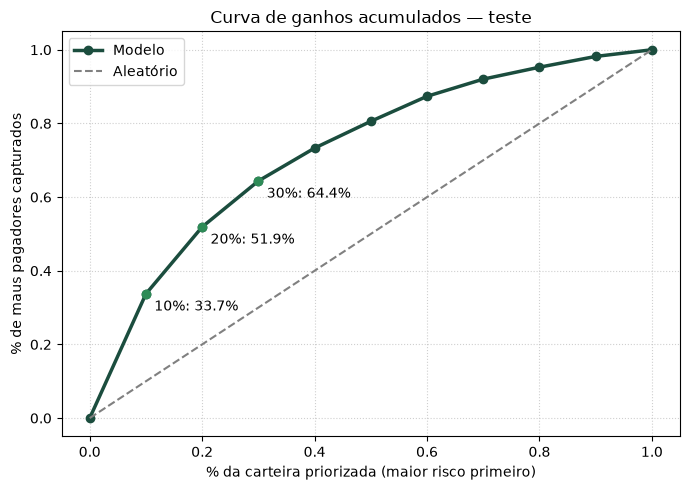

In [77]:
plt.figure(figsize=(7, 5))

plt.plot(
    [0] + tabela_teste["pct_pop_acum"].tolist(),
    [0] + tabela_teste["pct_bads_acum"].tolist(),
    color=GREEN_DARK,
    marker="o",
    linewidth=2.5,
    label="Modelo",
)
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Aleatório")

for fracao, rotulo in [(0.10, "10%"), (0.20, "20%"), (0.30, "30%")]:
    idx = (tabela_teste["pct_pop_acum"] >= fracao).idxmax()
    x = tabela_teste.loc[idx, "pct_pop_acum"]
    y = tabela_teste.loc[idx, "pct_bads_acum"]
    plt.scatter(x, y, color=GREEN_MID, zorder=5)
    plt.annotate(f"{rotulo}: {y:.1%}", (x, y), textcoords="offset points", xytext=(6, -12))

plt.xlabel("% da carteira priorizada (maior risco primeiro)")
plt.ylabel("% de maus pagadores capturados")
plt.title("Curva de ganhos acumulados — teste")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig("../reports/curva_ganhos_teste.png", dpi=150)
plt.show()

### 11.2 Lift por decil

Leitura: lift `1,0` significa risco igual à média. Lift `2,0` significa risco duas vezes maior que a média.

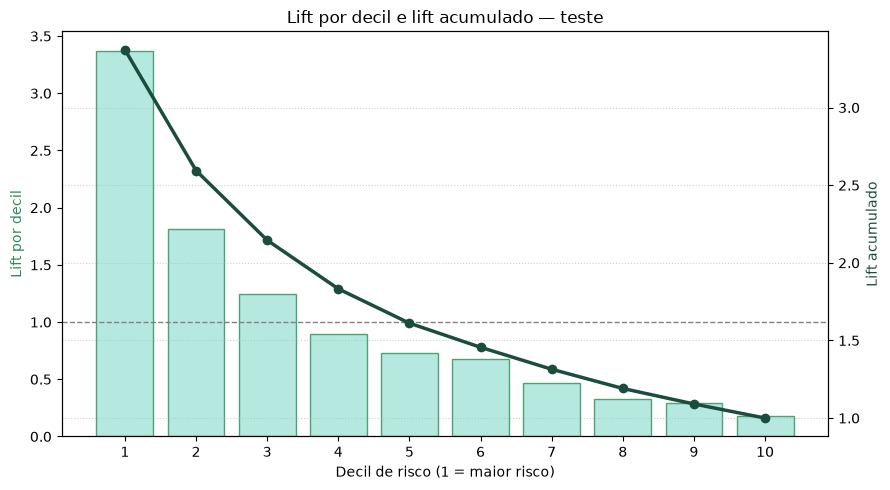

In [78]:
fig, ax1 = plt.subplots(figsize=(9, 5))
ax2 = ax1.twinx()

ax1.bar(
    tabela_teste["decil"],
    tabela_teste["lift"],
    color=GREEN_PALE,
    edgecolor=GREEN_MID,
    alpha=0.8,
    label="Lift por decil",
)
ax1.axhline(1, color="gray", linestyle="--", linewidth=1)
ax1.set_xlabel("Decil de risco (1 = maior risco)")
ax1.set_ylabel("Lift por decil", color=GREEN_MID)
ax1.set_xticks(tabela_teste["decil"])

ax2.plot(
    tabela_teste["decil"],
    tabela_teste["lift_acum"],
    color=GREEN_DARK,
    marker="o",
    linewidth=2.5,
    label="Lift acumulado",
)
ax2.set_ylabel("Lift acumulado", color=GREEN_DARK)

plt.title("Lift por decil e lift acumulado — teste")
ax1.grid(False)
ax2.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.savefig("../reports/lift_teste.png", dpi=150)
plt.show()

#### **11.3 Calibração por decil**

Leitura: as barras mostram o bad rate observado; a linha mostra a probabilidade média prevista. Quanto mais próximas, melhor a calibração.

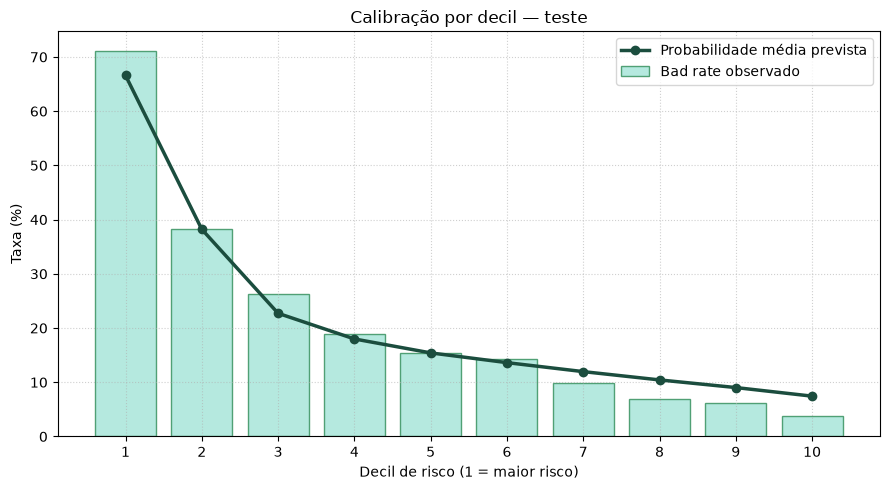

In [79]:
x = np.arange(len(tabela_teste))

plt.figure(figsize=(9, 5))
plt.bar(
    x,
    tabela_teste["bad_rate"] * 100,
    color=GREEN_PALE,
    edgecolor=GREEN_MID,
    alpha=0.8,
    label="Bad rate observado",
)
plt.plot(
    x,
    tabela_teste["prob_media"] * 100,
    color=GREEN_DARK,
    marker="o",
    linewidth=2.5,
    label="Probabilidade média prevista",
)
plt.xticks(x, tabela_teste["decil"])
plt.xlabel("Decil de risco (1 = maior risco)")
plt.ylabel("Taxa (%)")
plt.title("Calibração por decil — teste")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig("../reports/calibracao_teste.png", dpi=150)
plt.show()

### 11.4 Distribuição de score por classe

Leitura: quanto mais separadas as distribuições de bons e maus, melhor o poder discriminativo.

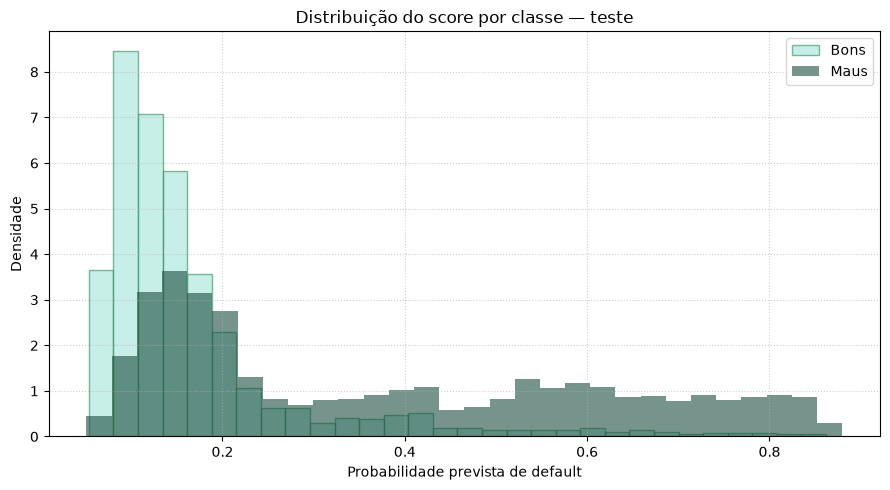

In [80]:
plt.figure(figsize=(9, 5))

plt.hist(
    resultados["teste"][teste[target] == 0],
    bins=30,
    density=True,
    alpha=0.6,
    color=GREEN_PALE,
    edgecolor=GREEN_MID,
    label="Bons",
)
plt.hist(
    resultados["teste"][teste[target] == 1],
    bins=30,
    density=True,
    alpha=0.6,
    color=GREEN_DARK,
    label="Maus",
)

plt.xlabel("Probabilidade prevista de default")
plt.ylabel("Densidade")
plt.title("Distribuição do score por classe — teste")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig("../reports/distribuicao_score_teste.png", dpi=150)
plt.show()

#### **11.5 Leitura executiva**

- **Ganhos:** percentual de maus capturados ao priorizar os maiores riscos.
- **Lift:** intensidade do risco em cada decil.
- **Calibração:** confiança nas probabilidades previstas.
- **Distribuição:** separação visual entre bons e maus.

Os gráficos são salvos em `reports/` e a tabela de decisão em `data/02_gold/tabela_decisao_teste.csv`.

##### **12. Calibração**

A calibração ajusta o **nível** das probabilidades, sem mudar a ordenação dos clientes. Portanto:

- lift, gains, AUC e KS permanecem praticamente iguais;
- probabilidades, perda esperada, provisão e política de limite ficam mais confiáveis.

O calibrador é ajustado em previsões **out-of-fold do treino** e comparado na validação. O teste é usado apenas na avaliação final.

In [81]:
def logit(p, eps=1e-6):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))


def expected_calibration_error(y, p, bins=10):
    limites = np.unique(np.quantile(p, np.linspace(0, 1, bins + 1)))
    indices = np.digitize(p, limites[1:-1])
    erro = 0.0

    for i in range(len(limites) - 1):
        mask = indices == i
        if mask.sum() == 0:
            continue
        erro += mask.mean() * abs(y[mask].mean() - p[mask].mean())

    return erro


def metricas_calibracao(y, p):
    return {
        "brier": brier_score_loss(y, p),
        "logloss": log_loss(y, p),
        "auc": roc_auc_score(y, p),
        "ece": expected_calibration_error(y, p),
        "prob_media": p.mean(),
        "bad_rate": y.mean(),
    }

In [82]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
prob_oof = np.zeros(len(treino))

for idx_treino, idx_validacao in kf.split(treino):
    modelo_fold = smf.logit(formula_final, data=treino.iloc[idx_treino]).fit(disp=0)
    prob_oof[idx_validacao] = modelo_fold.predict(treino.iloc[idx_validacao]).values

print("Previsões out-of-fold geradas:", len(prob_oof))

Previsões out-of-fold geradas: 18000


In [83]:
y_treino = treino[target].values
z_oof = logit(prob_oof).reshape(-1, 1)

calibrador_platt = LogisticRegression(
    C=1e6,
    solver="lbfgs",
    max_iter=1000,
).fit(z_oof, y_treino)

calibrador_isotonic = IsotonicRegression(out_of_bounds="clip").fit(prob_oof, y_treino)

calibrador_spline = make_pipeline(
    SplineTransformer(n_knots=5, degree=3, include_bias=False),
    LogisticRegression(C=1e6, solver="lbfgs", max_iter=2000),
).fit(z_oof, y_treino)

calibradores = {
    "platt": calibrador_platt,
    "isotonic": calibrador_isotonic,
    "spline": calibrador_spline,
}

print("Calibradores ajustados:", list(calibradores))

Calibradores ajustados: ['platt', 'isotonic', 'spline']


In [84]:
def aplicar_calibrador(metodo, probabilidades):
    if metodo == "original":
        return probabilidades

    calibrador = calibradores[metodo]

    if metodo == "isotonic":
        return calibrador.predict(probabilidades)

    z = logit(probabilidades).reshape(-1, 1)
    return calibrador.predict_proba(z)[:, 1]

In [85]:
linhas = []

for nome_base, base in [("validacao", validacao), ("teste", teste)]:
    y = base[target].values
    p_original = modelo_final.predict(base).values

    for metodo in ["original", "platt", "isotonic", "spline"]:
        p = aplicar_calibrador(metodo, p_original)
        resumo = metricas_calibracao(y, p)
        resumo["base"] = nome_base
        resumo["metodo"] = metodo
        linhas.append(resumo)

metricas_calibracao_df = pd.DataFrame(linhas)[[
    "base", "metodo", "brier", "logloss", "auc", "ece", "prob_media", "bad_rate"
]].sort_values(["base", "metodo"]).reset_index(drop=True)

metricas_calibracao_df.round(4)

,base,metodo,brier,logloss,auc,ece,prob_media,bad_rate
0,teste,isotonic,0.1286,0.4133,0.7893,0.0173,0.2136,0.2110
1,teste,original,0.1291,0.4156,0.7906,0.0222,0.2134,0.2110
2,teste,platt,0.1291,0.4157,0.7906,0.0228,0.2135,0.2110
3,teste,spline,0.1287,0.4135,0.7906,0.0182,0.2132,0.2110
4,validacao,isotonic,0.1265,0.4096,0.7779,0.0179,0.2112,0.2033
5,validacao,original,0.1267,0.4109,0.7781,0.0206,0.2114,0.2033
6,validacao,platt,0.1267,0.4110,0.7781,0.0210,0.2115,0.2033
7,validacao,spline,0.1265,0.4099,0.7782,0.0189,0.2110,0.2033


### **12.1 Escolha do método**

Critério: menor log loss na validação. Em caso de diferença inferior a `0.001`, prioriza-se o spline por ser mais suave e preservar melhor a AUC.

In [86]:
validacao_calibracao = metricas_calibracao_df.query("base == 'validacao'")
validacao_calibracao = validacao_calibracao[validacao_calibracao["metodo"] != "original"]

melhor_logloss = validacao_calibracao["logloss"].min()
candidatos = validacao_calibracao[validacao_calibracao["logloss"] <= melhor_logloss + 0.001]
metodo_escolhido = "spline" if "spline" in candidatos["metodo"].values else candidatos.sort_values("logloss").iloc[0]["metodo"]

print("Método escolhido:", metodo_escolhido)
validacao_calibracao.round(4)

Método escolhido: spline


,base,metodo,brier,logloss,auc,ece,prob_media,bad_rate
4,validacao,isotonic,0.1265,0.4096,0.7779,0.0179,0.2112,0.2033
6,validacao,platt,0.1267,0.4110,0.7781,0.0210,0.2115,0.2033
7,validacao,spline,0.1265,0.4099,0.7782,0.0189,0.2110,0.2033


In [87]:
y_validacao = validacao[target].values
p_validacao_original = modelo_final.predict(validacao).values
p_validacao_calibrada = aplicar_calibrador(metodo_escolhido, p_validacao_original)

y_teste = teste[target].values
p_teste_original = modelo_final.predict(teste).values
p_teste_calibrada = aplicar_calibrador(metodo_escolhido, p_teste_original)

metricas_finais_calibracao = pd.DataFrame([
    {"base": "validacao", "versao": "original", **metricas_calibracao(y_validacao, p_validacao_original)},
    {"base": "validacao", "versao": f"calibrado_{metodo_escolhido}", **metricas_calibracao(y_validacao, p_validacao_calibrada)},
    {"base": "teste", "versao": "original", **metricas_calibracao(y_teste, p_teste_original)},
    {"base": "teste", "versao": f"calibrado_{metodo_escolhido}", **metricas_calibracao(y_teste, p_teste_calibrada)},
])

metricas_finais_calibracao.round(4)

,base,versao,brier,logloss,auc,ece,prob_media,bad_rate
0,validacao,original,0.1267,0.4109,0.7781,0.0206,0.2114,0.2033
1,validacao,calibrado_spline,0.1265,0.4099,0.7782,0.0189,0.2110,0.2033
2,teste,original,0.1291,0.4156,0.7906,0.0222,0.2134,0.2110
3,teste,calibrado_spline,0.1287,0.4135,0.7906,0.0182,0.2132,0.2110


### **12.2 Curva de calibração no teste**

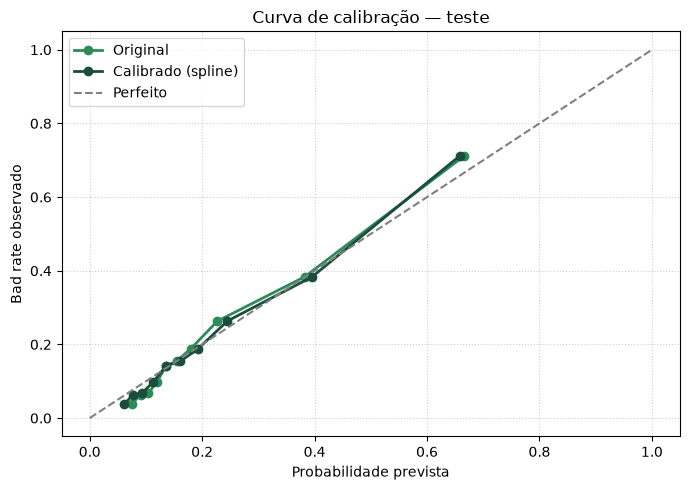

In [88]:
prob_true_original, prob_pred_original = calibration_curve(
    y_teste,
    p_teste_original,
    n_bins=10,
    strategy="quantile",
)

prob_true_calibrada, prob_pred_calibrada = calibration_curve(
    y_teste,
    p_teste_calibrada,
    n_bins=10,
    strategy="quantile",
)

plt.figure(figsize=(7, 5))

plt.plot(
    prob_pred_original,
    prob_true_original,
    marker="o",
    linewidth=2,
    color=GREEN_MID,
    label="Original",
)
plt.plot(
    prob_pred_calibrada,
    prob_true_calibrada,
    marker="o",
    linewidth=2,
    color=GREEN_DARK,
    label=f"Calibrado ({metodo_escolhido})",
)
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfeito")

plt.xlabel("Probabilidade prevista")
plt.ylabel("Bad rate observado")
plt.title("Curva de calibração — teste")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig("../reports/calibracao_comparativa_teste.png", dpi=150)
plt.show()

#### **12.3 Ponto de corte calibrado**

O corte é escolhido na validação, usando as probabilidades calibradas, e aplicado no teste.

In [89]:
fpr_val_cal, tpr_val_cal, thresholds_val_cal = roc_curve(y_validacao, p_validacao_calibrada)
indice_corte_cal = np.argmax(tpr_val_cal - fpr_val_cal)
corte_calibrado = thresholds_val_cal[indice_corte_cal]

predito_teste_cal = (p_teste_calibrada >= corte_calibrado).astype(int)
matriz_teste_cal = confusion_matrix(y_teste, predito_teste_cal)

print("Corte calibrado escolhido na validação:", round(corte_calibrado, 4))

pd.DataFrame(
    matriz_teste_cal,
    index=["Real 0", "Real 1"],
    columns=["Predito 0", "Predito 1"],
)

Corte calibrado escolhido na validação: 0.1964


,Predito 0,Predito 1
Real 0,3543,1191
Real 1,398,868


#### **12.4 Gravação dos artefatos de calibração**

In [90]:
metricas_calibracao_df.to_csv("../data/02_gold/metricas_calibracao.csv", index=False)
metricas_finais_calibracao.to_csv("../data/02_gold/metricas_calibracao_final.csv", index=False)

with open("../data/02_gold/calibrador.pkl", "wb") as file:
    pickle.dump({
        "metodo": metodo_escolhido,
        "calibrador": calibradores[metodo_escolhido],
        "corte_calibrado": corte_calibrado,
    }, file, protocol=pickle.HIGHEST_PROTOCOL)

scores_teste_calibrado = teste[["ID", "SAFRA", target]].copy()
scores_teste_calibrado["prob_original"] = p_teste_original
scores_teste_calibrado["prob_calibrada"] = p_teste_calibrada
scores_teste_calibrado["predito_calibrado"] = predito_teste_cal
scores_teste_calibrado.to_parquet("../data/02_gold/scores_teste_calibrado.parquet", index=False)

print("Método salvo:", metodo_escolhido)
print("Arquivos gravados em data/02_gold")

Método salvo: spline
Arquivos gravados em data/02_gold


#### **12.5 Leitura executiva**

- A calibração **não altera lift, gains, AUC ou KS**, pois preserva a ordenação.
- Ela melhora a qualidade das probabilidades, medida por Brier, log loss e ECE.
- O método escolhido foi o que apresentou melhor log loss na validação, com preferência pelo spline em caso de empate técnico.
- Use a probabilidade calibrada para decisões que dependem do **valor esperado de perda**, não apenas da ordem dos clientes.

#### **12.6 Modelo portável**

O pickle de um modelo `statsmodels` com fórmula pode depender do ambiente de `patsy` na hora de recarregar. Para uso fora do notebook, salvamos também uma versão portável com fórmula, variáveis, intercepto e coeficientes.

In [91]:
modelo_portavel = {
    "formula": formula_final,
    "variaveis": variaveis_finais,
    "intercepto": float(modelo_final.params["Intercept"]),
    "coeficientes": {var: float(modelo_final.params[var]) for var in variaveis_finais},
}

with open("../data/02_gold/modelo_logistico_portavel.pkl", "wb") as file:
    pickle.dump(modelo_portavel, file, protocol=pickle.HIGHEST_PROTOCOL)

with open("../data/02_gold/modelo_logistico_portavel.json", "w") as file:
    json.dump(modelo_portavel, file, indent=2)


def prever_modelo_portavel(base, modelo):
    X = np.column_stack([
        np.ones(len(base)),
        *[base[var].values for var in modelo["variaveis"]],
    ])
    beta = np.array(
        [modelo["intercepto"]] + [modelo["coeficientes"][var] for var in modelo["variaveis"]]
    )
    return 1 / (1 + np.exp(-X @ beta))

In [92]:
prob_portavel = prever_modelo_portavel(teste, modelo_portavel)
prob_statsmodels = modelo_final.predict(teste).values

print("Maior diferença absoluta:", np.abs(prob_portavel - prob_statsmodels).max())
print("Previsões equivalentes:", np.allclose(prob_portavel, prob_statsmodels, atol=1e-10))

Maior diferença absoluta: 2.220446049250313e-16
Previsões equivalentes: True
